In [1]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import torch
import torch.nn as nn
from sklearn.ensemble import IsolationForest
from sklearn.model_selection import train_test_split

SEED = 67
np.random.seed(SEED)
torch.manual_seed(SEED)
random.seed(SEED)

MODEL_DIR = "../models"
ART_DIR = "../artifacts"
RESULT_DIR = "../results"
PLOT_DIR = "../results/plots"
os.makedirs(PLOT_DIR, exist_ok=True)

with np.load(os.path.join(ART_DIR, "clean_data.npz"), allow_pickle=False) as data:
    X_val, y_val = data["X_val"], data["y_val"]
    X_test, y_test = data["X_test"], data["y_test"]
with np.load(os.path.join(ART_DIR, "poisoned_data.npz"), allow_pickle=False) as data:
    X_test_attacks_poisoned = data["X_test_attacks_poisoned"]
    test_attack_indices = data["test_attack_indices"]
assert np.array_equal(test_attack_indices, np.flatnonzero(y_test == 1))
assert len(X_test_attacks_poisoned) == len(test_attack_indices)

benign_val_indices = np.flatnonzero(y_val == 0)
fit_indices, calibration_indices = train_test_split(
    benign_val_indices, test_size=0.5, random_state=SEED
)
assert set(fit_indices).isdisjoint(calibration_indices)
X_fit = X_val[fit_indices]
X_calibration = X_val[calibration_indices]
TARGET_FPR = 0.03
print(f"Trusted benign samples: {len(X_fit)} for fitting, {len(X_calibration)} calibration")
benign = y_test == 0


Trusted benign samples: 3367 for fitting, 3368 calibration


In [2]:
# DNN ARCHITECTURE 
__torch_device = None
def get_torch_device():
    global __torch_device
    if __torch_device is not None:
        return __torch_device
    if  torch.backends.mps.is_available():
        print('Using MPS device for hardware acceleration')
        __torch_device = 'mps'
    elif torch.cuda.is_available():
        print('Using CUDA device for hardware acceleration')
        __torch_device = 'cuda'
    else:
        print('Hardware acceleration not available, using CPU')
        __torch_device = 'cpu'
    return __torch_device

device = get_torch_device()

class DNN(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 128),   # 0
            nn.ReLU(),                   # 1
            nn.BatchNorm1d(128),         # 2
            nn.Dropout(0.2),             # 3
            nn.Linear(128, 64),          # 4
            nn.ReLU(),                   # 5
            nn.BatchNorm1d(64),          # 6
            nn.Dropout(0.2),             # 7
            nn.Linear(64, 1)             # 8
        )

    def forward(self, x, return_activations=False):
        acts = self.net[:8](x)           # input to the final Linear layer (64D penultimate representation)
        logits = self.net[8](acts)
        if return_activations:
            return logits, acts
        return logits


model = DNN(X_test.shape[1]).to(device)
model.load_state_dict(torch.load(
    os.path.join(MODEL_DIR, "poisoned", "poisoned_dnn_model.pth"),
    map_location=device, weights_only=True
))
model.eval()

Using MPS device for hardware acceleration


DNN(
  (net): Sequential(
    (0): Linear(in_features=41, out_features=128, bias=True)
    (1): ReLU()
    (2): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): ReLU()
    (6): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (7): Dropout(p=0.2, inplace=False)
    (8): Linear(in_features=64, out_features=1, bias=True)
  )
)

In [3]:
def extract_activations(X, network=None):
    network = model if network is None else network
    network.eval()
    activations = []
    with torch.no_grad():
        for start in range(0, len(X), 2048):
            batch = torch.tensor(X[start:start+2048], dtype=torch.float32).to(device)
            _, acts = network(batch, return_activations=True)
            activations.append(acts.cpu().numpy())
    return np.vstack(activations)

# both methods see exactly the same fit/calibration connections
representations = {
    "features": {"fit": X_fit, "calibration": X_calibration},
    "activations": {"fit": extract_activations(X_fit),
                    "calibration": extract_activations(X_calibration)},
}
detectors = {}
for name, representation in representations.items():
    detector = IsolationForest(n_estimators=100, contamination="auto", random_state=SEED, n_jobs=-1)
    detector.fit(representation["fit"])
    # higher score = more anomalous
    calibration_scores = -detector.score_samples(representation["calibration"])
    threshold = np.quantile(calibration_scores, 1 - TARGET_FPR, method="higher")
    calibration_fpr = np.mean(calibration_scores > threshold)
    detectors[name] = {"model": detector, "threshold": float(threshold),
                       "calibration_fpr": float(calibration_fpr)}
    print(f"{name}: threshold={threshold:.4f}, Calibration FPR={calibration_fpr:.4f}")

features: threshold=0.5289, Calibration FPR=0.0300
activations: threshold=0.4976, Calibration FPR=0.0300


In [4]:
def dnn_predictions(X, network=None):
    network = model if network is None else network
    network.eval()
    predictions = []
    with torch.no_grad():
        for start in range(0, len(X), 2048):
            batch = torch.tensor(X[start:start+2048], dtype=torch.float32).to(device)
            predictions.append((torch.sigmoid(network(batch)) >= 0.5).cpu().numpy().reshape(-1))
    return np.concatenate(predictions)


def evaluate_case(network, triggered_X, case_detectors):
    pred_test = dnn_predictions(X_test, network)
    pred_trigger = dnn_predictions(triggered_X, network)
    benign = y_test == 0
    evaded = pred_trigger == 0
    print(f"DNN alone: ASR={evaded.mean():.4f}, FPR={pred_test[benign].mean():.4f}, "
          f"attack recall={pred_test[~benign].mean():.4f}")

    test_representations = {
        "features": (X_test, triggered_X),
        "activations": (extract_activations(X_test, network), extract_activations(triggered_X, network)),
    }
    rows, test_results = [], {}
    for name, (original, triggered) in test_representations.items():
        detector, threshold = case_detectors[name]["model"], case_detectors[name]["threshold"]
        scores = -detector.score_samples(original)
        trigger_scores = -detector.score_samples(triggered)
        flagged = scores > threshold
        trigger_flagged = trigger_scores > threshold
        system_alert = pred_test | flagged
        residual_escape = evaded & ~trigger_flagged
        rows.append({
            "representation": name,
            "calibration_fpr": case_detectors[name]["calibration_fpr"],
            "benign_flag_rate": float(flagged[benign].mean()),
            "clean_attack_flag_rate": float(flagged[~benign].mean()),
            "trigger_detection_rate": float(trigger_flagged.mean()),
            "detection_among_dnn_evasions": float(trigger_flagged[evaded].mean()) if evaded.any() else np.nan,
            "system_residual_asr": float(residual_escape.mean()),
            "system_benign_false_alarm": float(system_alert[benign].mean()),
            "system_clean_attack_recall": float(system_alert[~benign].mean()),
            "n_test_benign": int(benign.sum()), "n_test_attacks": int((~benign).sum()),
            "n_dnn_evasions": int(evaded.sum()), "n_residual_evasions": int(residual_escape.sum()),
        })
        test_results[name] = {"scores": scores, "trigger_scores": trigger_scores,
                              "flagged": flagged, "trigger_flagged": trigger_flagged,
                              "residual_escape": residual_escape}
    results = pd.DataFrame(rows).set_index("representation")
    print("\nComparison (rates between 0 and 1):")
    print(results.to_string(float_format=lambda value: f"{value:.4f}"))
    return results, test_results, pred_test, pred_trigger

print("=== ORIGINAL TRIGGER ===")
results, test_results, pred_test, pred_trigger = evaluate_case(model, X_test_attacks_poisoned, detectors)


=== ORIGINAL TRIGGER ===
DNN alone: ASR=1.0000, FPR=0.0235, attack recall=0.6469

Comparison (rates between 0 and 1):
                calibration_fpr  benign_flag_rate  clean_attack_flag_rate  trigger_detection_rate  detection_among_dnn_evasions  system_residual_asr  system_benign_false_alarm  system_clean_attack_recall  n_test_benign  n_test_attacks  n_dnn_evasions  n_residual_evasions
representation                                                                                                                                                                                                                                                                 
features                 0.0300            0.0171                  0.6303                  0.8118                        0.8118               0.1882                     0.0312                      0.7284           9711           12833           12833                 2415
activations              0.0300            0.0852                 

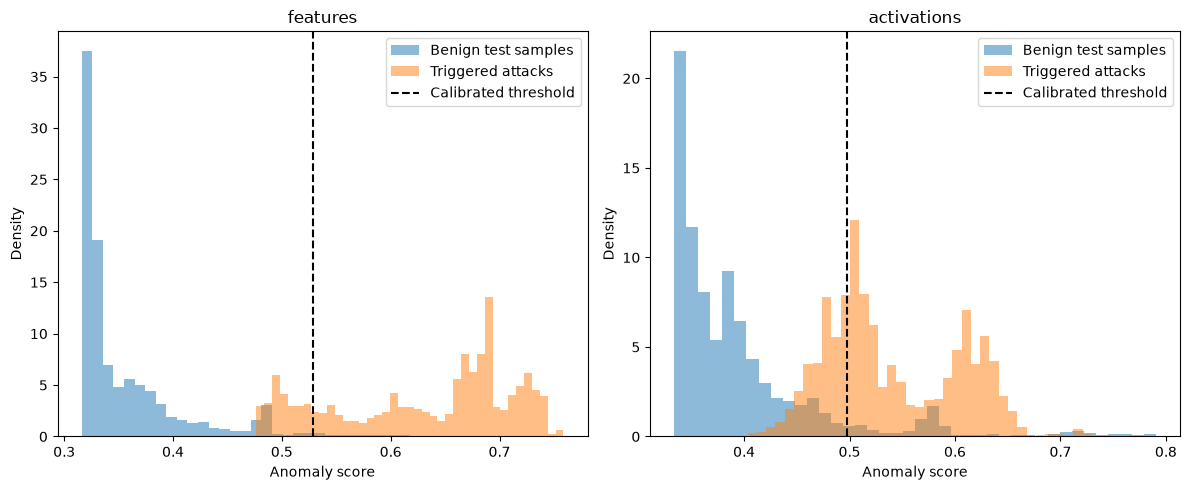

In [5]:
# original trigger
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for axis, name in zip(axes, ["features", "activations"]):
    scores = test_results[name]["scores"]
    axis.hist(scores[benign], bins=40, density=True, alpha=0.5, label="Benign test samples")
    axis.hist(test_results[name]["trigger_scores"], bins=40, density=True, alpha=0.5,
              label="Triggered attacks")
    axis.axvline(detectors[name]["threshold"], color="black", linestyle="--", label="Calibrated threshold")
    axis.set_title(name)
    axis.set_xlabel("Anomaly score")
    axis.set_ylabel("Density")
    axis.legend()
fig.tight_layout()
fig.savefig(os.path.join(PLOT_DIR, "defense_score_comparison.png"), dpi=150, bbox_inches="tight")
plt.show()

In [6]:
with np.load(os.path.join(ART_DIR, "poisoned_data_variant.npz"), allow_pickle=False) as data:
    X_test_attacks_variant = data["X_test_attacks_poisoned"]
    assert np.array_equal(test_attack_indices, data["test_attack_indices"])

variant_model = DNN(X_test.shape[1]).to(device)
variant_model.load_state_dict(torch.load(
    os.path.join(MODEL_DIR, "poisoned", "poisoned_dnn_variant.pth"),
    map_location=device, weights_only=True
))
variant_model.eval()
clean_model = DNN(X_test.shape[1]).to(device)
clean_model.load_state_dict(torch.load(
    os.path.join(MODEL_DIR, "clean", "clean_dnn_model.pth"),
    map_location=device, weights_only=True
))
clean_model.eval()

def fit_activation_detector(network):
    detector = IsolationForest(n_estimators=100, contamination="auto", random_state=SEED, n_jobs=-1)
    detector.fit(extract_activations(X_fit, network))
    calibration_scores = -detector.score_samples(extract_activations(X_calibration, network))
    threshold = float(np.quantile(calibration_scores, 1 - TARGET_FPR, method="higher"))
    return {"model": detector, "threshold": threshold,
            "calibration_fpr": float(np.mean(calibration_scores > threshold))}

variant_detectors = {"features": detectors["features"],
                     "activations": fit_activation_detector(variant_model)}
clean_activation_detector = fit_activation_detector(clean_model)
print("\n=== 99TH-PERCENTILE TRIGGER ===")
variant_results, variant_test_results, variant_pred_test, variant_pred_trigger = evaluate_case(
    variant_model, X_test_attacks_variant, variant_detectors
)
comparison = pd.concat({"max": results, "quantile_99": variant_results}, names=["trigger"])
print("\n=== DEFENSE COMPARISON ===")
print(comparison[["trigger_detection_rate", "benign_flag_rate", "system_residual_asr",
                  "system_benign_false_alarm"]].to_string(float_format=lambda value: f"{value:.4f}"))


=== 99TH-PERCENTILE TRIGGER ===
DNN alone: ASR=0.9652, FPR=0.0244, attack recall=0.6393

Comparison (rates between 0 and 1):
                calibration_fpr  benign_flag_rate  clean_attack_flag_rate  trigger_detection_rate  detection_among_dnn_evasions  system_residual_asr  system_benign_false_alarm  system_clean_attack_recall  n_test_benign  n_test_attacks  n_dnn_evasions  n_residual_evasions
representation                                                                                                                                                                                                                                                                 
features                 0.0300            0.0171                  0.6303                  0.7249                        0.7379               0.2530                     0.0317                      0.7333           9711           12833           12387                 3247
activations              0.0300            0.0895         

In [7]:
control_detector = clean_activation_detector["model"]
control_threshold = clean_activation_detector["threshold"]
control_test_scores = -control_detector.score_samples(extract_activations(X_test, clean_model))
control_test_flags = control_test_scores > control_threshold
control_rows, control_trigger_results = [], {}
for name, triggered_X, poisoned_result in [
    ("max", X_test_attacks_poisoned, results),
    ("quantile_99", X_test_attacks_variant, variant_results),
]:
    scores = -control_detector.score_samples(extract_activations(triggered_X, clean_model))
    flags = scores > control_threshold
    control_trigger_results[name] = {"scores": scores, "flagged": flags}
    control_rows.append({
        "trigger": name,
        "clean_activation_calibration_fpr": clean_activation_detector["calibration_fpr"],
        "clean_activation_trigger_detection": float(flags.mean()),
        "poisoned_activation_trigger_detection": poisoned_result.loc["activations", "trigger_detection_rate"],
        "clean_activation_benign_flag_rate": float(control_test_flags[benign].mean()),
        "poisoned_activation_benign_flag_rate": poisoned_result.loc["activations", "benign_flag_rate"],
        "clean_activation_clean_attack_flag_rate": float(control_test_flags[~benign].mean()),
        "poisoned_activation_clean_attack_flag_rate": poisoned_result.loc["activations", "clean_attack_flag_rate"],
    })
clean_control = pd.DataFrame(control_rows).set_index("trigger")
print("\n=== CLEAN DNN ACTIVATION CONTROL ===")
print(clean_control.to_string(float_format=lambda value: f"{value:.4f}"))


=== CLEAN DNN ACTIVATION CONTROL ===
             clean_activation_calibration_fpr  clean_activation_trigger_detection  poisoned_activation_trigger_detection  clean_activation_benign_flag_rate  poisoned_activation_benign_flag_rate  clean_activation_clean_attack_flag_rate  poisoned_activation_clean_attack_flag_rate
trigger                                                                                                                                                                                                                                                                               
max                                    0.0300                              0.9988                                 0.7095                             0.0838                                0.0852                                   0.7187                                      0.7444
quantile_99                            0.0300                              0.7460                                 0.3687     

In [8]:
joblib.dump({"seed": SEED, "target_fpr": TARGET_FPR, "detectors": detectors,
             "fit_indices_in_validation": fit_indices,
             "calibration_indices_in_validation": calibration_indices},
            os.path.join(MODEL_DIR, "backdoor_detectors.joblib"))
results.to_csv(os.path.join(RESULT_DIR, "defense_metrics.csv"))
np.savez(
    os.path.join(ART_DIR, "defense_results.npz"),
    test_attack_indices=test_attack_indices,
    dnn_test_predictions=pred_test, dnn_trigger_predictions=pred_trigger,
    feature_test_flags=test_results["features"]["flagged"],
    feature_trigger_flags=test_results["features"]["trigger_flagged"],
    activation_test_flags=test_results["activations"]["flagged"],
    activation_trigger_flags=test_results["activations"]["trigger_flagged"],
    feature_trigger_scores=test_results["features"]["trigger_scores"],
    activation_trigger_scores=test_results["activations"]["trigger_scores"],
)
print("Detectors, thresholds, metrics, and explainability results saved\nDNN weights unchanged")

Detectors, thresholds, metrics, and explainability results saved
DNN weights unchanged


In [9]:
# extending the bundle without changing the feature/main-activation detector keys
joblib.dump({"seed": SEED, "target_fpr": TARGET_FPR, "detectors": detectors,
             "variant_detectors": variant_detectors,
             "clean_activation_detector": clean_activation_detector,
             "fit_indices_in_validation": fit_indices,
             "calibration_indices_in_validation": calibration_indices},
            os.path.join(MODEL_DIR, "backdoor_detectors.joblib"))
variant_results.to_csv(os.path.join(RESULT_DIR, "defense_metrics_variant.csv"))
comparison.to_csv(os.path.join(RESULT_DIR, "defense_trigger_comparison.csv"))
clean_control.to_csv(os.path.join(RESULT_DIR, "defense_clean_control.csv"))
np.savez(
    os.path.join(ART_DIR, "defense_results_variant.npz"),
    test_attack_indices=test_attack_indices,
    dnn_test_predictions=variant_pred_test, dnn_trigger_predictions=variant_pred_trigger,
    feature_test_flags=variant_test_results["features"]["flagged"],
    feature_trigger_flags=variant_test_results["features"]["trigger_flagged"],
    activation_test_flags=variant_test_results["activations"]["flagged"],
    activation_trigger_flags=variant_test_results["activations"]["trigger_flagged"],
    feature_trigger_scores=variant_test_results["features"]["trigger_scores"],
    activation_trigger_scores=variant_test_results["activations"]["trigger_scores"],
)
np.savez(
    os.path.join(ART_DIR, "defense_clean_control.npz"),
    test_attack_indices=test_attack_indices, test_flags=control_test_flags,
    max_trigger_flags=control_trigger_results["max"]["flagged"],
    max_trigger_scores=control_trigger_results["max"]["scores"],
    variant_trigger_flags=control_trigger_results["quantile_99"]["flagged"],
    variant_trigger_scores=control_trigger_results["quantile_99"]["scores"],
    threshold=np.array(control_threshold),
)
print("Variant and clean control saved\nMain-case files remain compatible with explainability")

Variant and clean control saved
Main-case files remain compatible with explainability
